# TAHAP 2 - SEGMENTASI (adaptif per kelas dan per gambar, teknik BKPM)

**Input** : `hasil/01_cleaning/bersih/<kelas>/*.jpg`

**Output** (`hasil/02_segmentasi/`):

| Folder / file | Isi |
|---|---|
| `kontras/<kelas>/` | citra setelah median + Gaussian + contrast stretching / histeq |
| `mask/<kelas>/*.png` | peta instans: 0 = latar, 1..n = objek ke-n (dibaca tahap 3 dan 4) |
| `hasil_segmentasi/` | objek saja, latar dihitamkan |
| `overlay/` | kontur objek di atas gambar asli |
| `visualisasi_proses/` | subplot: asli, kontras, tepi Canny, kandidat terbaik, hasil, overlay |
| `laporan_segmentasi.csv` | metode terpilih, skor, status tiap gambar |
| `perlu_cek.txt` | gambar yang sebaiknya dikoreksi |

**Status**

| Status | Arti |
|---|---|
| `ok` | skor baik, dipakai langsung |
| `perlu_cek` | skor rendah; tetap dihasilkan, periksa overlay-nya |
| `cadangan_roi` | semua metode gagal, dipakai ROI pusat (kasar); sebaiknya beri ROI manual |
| `roi_manual` | ROI ditandai lewat notebook 02b (Acara 15) |

Letakkan notebook ini di `notebooks/`; `config.py`, `seg_core.py`, `seg_profil.py`, `refine_batas.py`, `bkpm.py`, `util.py` ada di `scripts/`.

## 1. Setup dan import

In [15]:
import sys, os
from pathlib import Path

SCRIPTS = Path.cwd().resolve().parent / "scripts"
if not SCRIPTS.is_dir():
    SCRIPTS = Path.cwd().resolve()
sys.path.insert(0, str(SCRIPTS))

# Opsional: bila folder proyek bukan induk dari scripts/, hilangkan tanda # dan isi path-nya
# os.environ["PROYEK_ROOT"] = r"D:\rompi-cerdas-fin"

import cv2
import numpy as np
from IPython.display import Image, display

import bkpm
import refine_batas
from config import CLASSES, D_CLEAN, D_SEG, ROOT
from seg_core import segmentasi_gambar
from util import baca_csv, baca_gambar, bersihkan, daftar_gambar, log, simpan_gambar, tabel, tulis_csv

TAHAP = "02_segmentasi"
ROI_CSV = ROOT / "roi_manual.csv"
KOLOM = ["kelas", "file", "n_objek", "metode", "skor", "status", "luas_rel", "kontras", "fit", "sep", "luas", "pos",
         "bentuk", "sentuh"]
WARNA = [(0, 255, 0), (0, 200, 255), (255, 120, 0), (255, 0, 200), (0, 0, 255), (200, 255, 0),
         (255, 255, 0), (120, 0, 255)]

print("Folder scripts :", SCRIPTS)
print("Folder proyek  :", ROOT)
print("Input bersih   :", D_CLEAN / "bersih")
print("Folder hasil   :", D_SEG)
print("File ROI manual:", ROI_CSV, "| ada:", ROI_CSV.exists())

Folder scripts : C:\Projek\vestcare-dataset\scripts
Folder proyek  : C:\Projek\vestcare-dataset
Input bersih   : C:\Projek\vestcare-dataset\hasil\01_cleaning\bersih
Folder hasil   : C:\Projek\vestcare-dataset\hasil\02_segmentasi
File ROI manual: C:\Projek\vestcare-dataset\roi_manual.csv | ada: True


## 2. Parameter

Setara argumen CLI skrip asli (`--kelas`, `--haluskan`, `--maks`).

In [16]:
KELAS_TERPILIH = None   # None = semua kelas; atau mis. "pohon"
MAKS = 0                # 0 = semua gambar; mis. 20 = uji cepat (sampel merata per kelas)
HALUSKAN = False        # True = rapikan batas mask gambar ber-ROI manual (refine_batas.py)

kelas_list = [KELAS_TERPILIH] if KELAS_TERPILIH else CLASSES
print("Kelas diproses:", kelas_list, "| maks:", MAKS or "semua", "| haluskan:", HALUSKAN)

Kelas diproses: ['pohon', 'lubang', 'orang', 'motor', 'mobil'] | maks: semua | haluskan: False


## 3. Fungsi bantu tampilan

`gambar_overlay` menggambar kontur objek, `subplot` menyusun citra berdampingan (padanan `subplot(1,n,k)` di BKPM), `tampil` dan `tampil_baris` menampilkan citra langsung di notebook.

In [17]:
def muat_roi():
    """roi_manual.csv: kolom file,x,y,w,h (piksel pada gambar bersih)."""
    return {r["file"]: (int(r["x"]), int(r["y"]), int(r["w"]), int(r["h"])) for r in baca_csv(ROI_CSV)}


def gambar_overlay(img, lab, teks=None):
    out = img.copy()
    n = int(lab.max())
    for i in range(1, n + 1):
        m = (lab == i).astype(np.uint8)
        w = WARNA[(i - 1) % len(WARNA)]
        out[m > 0] = (0.6 * out[m > 0] + 0.4 * np.array(w)).astype(np.uint8)
        k, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, k, -1, w, 2)
    if teks:
        cv2.putText(out, teks, (6, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 3, cv2.LINE_AA)
        cv2.putText(out, teks, (6, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1, cv2.LINE_AA)
    return out


def subplot(tiles, tinggi=220):
    """Susun beberapa citra berdampingan (padanan subplot(1,n,k) di BKPM)."""
    out = []
    for t in tiles:
        if t.ndim == 2:
            t = cv2.cvtColor(t, cv2.COLOR_GRAY2BGR)
        s = tinggi / t.shape[0]
        out.append(cv2.resize(t, (max(1, int(t.shape[1] * s)), tinggi), interpolation=cv2.INTER_AREA))
    return np.hstack(out)


def tampil(img, maks=1100):
    h, w = img.shape[:2]
    s = min(1.0, maks / max(h, w))
    if s < 1.0:
        img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    display(Image(data=cv2.imencode(".png", img)[1].tobytes()))


def tampil_baris(daftar, tinggi=190, per_baris=4):
    """daftar = [(citra BGR, teks)]"""
    for i in range(0, len(daftar), per_baris):
        ubin = []
        for im, teks in daftar[i:i + per_baris]:
            s = tinggi / im.shape[0]
            t = cv2.resize(im, (max(1, int(im.shape[1] * s)), tinggi), interpolation=cv2.INTER_AREA)
            cv2.putText(t, teks, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0, 0, 0), 3, cv2.LINE_AA)
            cv2.putText(t, teks, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            ubin.append(t)
        tampil(np.hstack(ubin))

print("fungsi siap")

fungsi siap


## 4. Inventaris input

Jumlah gambar bersih per kelas dan jumlah gambar yang sudah punya ROI manual.

In [18]:
roi = muat_roi()
inv = []
for k in kelas_list:
    fs = daftar_gambar(D_CLEAN / "bersih" / k)
    inv.append({"kelas": k, "gambar_bersih": len(fs), "punya_roi_manual": sum(p.name in roi for p in fs)})
tabel("Inventaris input tahap 2", inv, ["kelas", "gambar_bersih", "punya_roi_manual"])
if not any(r["gambar_bersih"] for r in inv):
    print("\nBelum ada gambar bersih. Jalankan notebook 01_cleaning dulu.")


Inventaris input tahap 2
kelas   gambar_bersih  punya_roi_manual
pohon   187            64              
lubang  317            186             
orang   123            70              
motor   220            196             
mobil   200            154             


## 5. Demo proses pada satu gambar

Memperlihatkan hasil tiap langkah untuk satu gambar: **asli | kontras | tepi Canny | kandidat terbaik | hasil | overlay**, beserta metode terpilih dan rincian skornya (`fit`, `sep`, `luas`, `pos`, `bentuk`, `sentuh`).

File          : pohon_primer-pohon-1.jpg (pohon)
Metode kontras: imadjust
Metode objek  : fusi_semua | skor 0.803 | status roi_manual | n objek 1
Rincian skor  : {'fit': 0.75, 'sep': 0.61, 'luas': 1.0, 'pos': np.float64(0.77), 'bentuk': 0.9, 'sentuh': 1.0}
Urutan panel  : asli | kontras | tepi Canny | kandidat terbaik | hasil | overlay


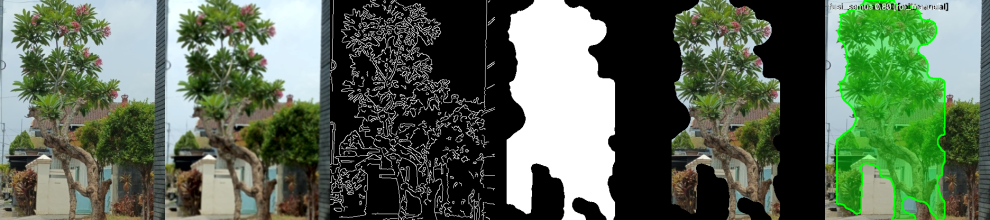

In [19]:
contoh = None
for k in kelas_list:
    fs = daftar_gambar(D_CLEAN / "bersih" / k)
    if fs:
        contoh, kelas_contoh = fs[0], k
        break

if contoh is None:
    print("Tidak ada gambar bersih.")
else:
    img = baca_gambar(contoh)
    r = segmentasi_gambar(img, kelas_contoh, roi.get(contoh.name))
    lab, P = r["label"], r["P"]
    obj = img.copy()
    obj[lab == 0] = 0
    teks = f"{r['metode']} {r['skor']:.2f} [{r['status']}]"
    ov = gambar_overlay(img, lab, teks)
    print("File          :", contoh.name, f"({kelas_contoh})")
    print("Metode kontras:", P["metode_kontras"])
    print("Metode objek  :", r["metode"], "| skor", round(r["skor"], 3), "| status", r["status"], "| n objek", r["n"])
    print("Rincian skor  :", {k: round(v, 2) for k, v in r["rinci"].items()})
    print("Urutan panel  : asli | kontras | tepi Canny | kandidat terbaik | hasil | overlay")
    tampil(subplot([img, P["kontras"], (P["tepi"] * 255).astype(np.uint8),
                    (lab > 0).astype(np.uint8) * 255, obj, ov]))

## 6. Proses segmentasi seluruh gambar

Untuk tiap gambar: segmentasi adaptif -> simpan kontras, mask, hasil, overlay, visualisasi proses -> catat ke laporan.

> Bila semua kelas diproses, folder `hasil/02_segmentasi/` dihapus dan dibuat ulang. Bila hanya sebagian kelas, hasil kelas lain dipertahankan.

In [20]:
if len(kelas_list) == len(CLASSES):
    bersihkan(D_SEG)
roi = muat_roi()
laporan = []

for kelas in kelas_list:
    files = daftar_gambar(D_CLEAN / "bersih" / kelas)
    if MAKS:
        files = files[::max(1, len(files) // MAKS)][:MAKS]
    if not files:
        log(TAHAP, f"tidak ada gambar bersih untuk '{kelas}' (jalankan notebook 01_cleaning)")
        continue
    for sub in ("kontras", "mask", "hasil_segmentasi", "overlay", "visualisasi_proses"):
        (D_SEG / sub / kelas).mkdir(parents=True, exist_ok=True)
    log(TAHAP, f"{kelas}: {len(files)} gambar")
    for i, p in enumerate(files, 1):
        img = baca_gambar(p)
        r = segmentasi_gambar(img, kelas, roi.get(p.name))
        lab, P = r["label"], r["P"]
        if HALUSKAN and p.name in roi:
            lab = refine_batas.refine(img, lab, roi[p.name], P)
        stem = p.stem

        simpan_gambar(D_SEG / "kontras" / kelas / f"{stem}.jpg", P["kontras"])
        cv2.imencode(".png", lab)[1].tofile(str(D_SEG / "mask" / kelas / f"{stem}.png"))
        obj = img.copy()
        obj[lab == 0] = 0
        simpan_gambar(D_SEG / "hasil_segmentasi" / kelas / f"{stem}.jpg", obj)
        teks = f"{r['metode']} {r['skor']:.2f} [{r['status']}]"
        ov = gambar_overlay(img, lab, teks)
        simpan_gambar(D_SEG / "overlay" / kelas / f"{stem}.jpg", ov, 90)
        vis = subplot([img, P["kontras"], (P["tepi"] * 255).astype(np.uint8),
                       (lab > 0).astype(np.uint8) * 255, obj, ov])
        simpan_gambar(D_SEG / "visualisasi_proses" / kelas / f"{stem}.jpg", vis, 85)

        rinci = r["rinci"]
        laporan.append({
            "kelas": kelas, "file": p.name, "n_objek": r["n"], "metode": r["metode"],
            "skor": f"{r['skor']:.3f}", "status": r["status"],
            "luas_rel": f"{(lab > 0).mean():.3f}", "kontras": P["metode_kontras"],
            **{k: f"{rinci.get(k, 0):.2f}" for k in ("fit", "sep", "luas", "pos", "bentuk", "sentuh")}})
        if i % 50 == 0:
            log(TAHAP, f"  {kelas}: {i}/{len(files)}")

print(f"\nTotal gambar disegmentasi: {len(laporan)}")

[02_segmentasi] pohon: 187 gambar
[02_segmentasi]   pohon: 50/187
[02_segmentasi]   pohon: 100/187
[02_segmentasi]   pohon: 150/187
[02_segmentasi] lubang: 317 gambar
[02_segmentasi]   lubang: 50/317
[02_segmentasi]   lubang: 100/317
[02_segmentasi]   lubang: 150/317
[02_segmentasi]   lubang: 200/317
[02_segmentasi]   lubang: 250/317
[02_segmentasi]   lubang: 300/317
[02_segmentasi] orang: 123 gambar
[02_segmentasi]   orang: 50/123
[02_segmentasi]   orang: 100/123
[02_segmentasi] motor: 220 gambar
[02_segmentasi]   motor: 50/220
[02_segmentasi]   motor: 100/220
[02_segmentasi]   motor: 150/220
[02_segmentasi]   motor: 200/220
[02_segmentasi] mobil: 200 gambar
[02_segmentasi]   mobil: 50/200
[02_segmentasi]   mobil: 100/200
[02_segmentasi]   mobil: 150/200
[02_segmentasi]   mobil: 200/200

Total gambar disegmentasi: 1047


## 7. Simpan laporan dan daftar `perlu_cek.txt`

Bila hanya sebagian kelas diproses, baris kelas lain di laporan dipertahankan.

In [21]:
lama = [r for r in baca_csv(D_SEG / "laporan_segmentasi.csv") if r["kelas"] not in kelas_list]
semua = lama + laporan
tulis_csv(D_SEG / "laporan_segmentasi.csv", semua, KOLOM)
cek = [f"{r['kelas']}/{r['file']}\t{r['status']}\t{r['metode']}\t{r['skor']}" for r in semua
       if r["status"] in ("perlu_cek", "cadangan_roi")]
(D_SEG / "perlu_cek.txt").write_text("\n".join(cek), encoding="utf-8")
log(TAHAP, f"laporan -> {D_SEG / 'laporan_segmentasi.csv'} ({len(semua)} baris)")
log(TAHAP, f"{len(cek)} gambar perlu dicek -> {D_SEG / 'perlu_cek.txt'}")

[02_segmentasi] laporan -> C:\Projek\vestcare-dataset\hasil\02_segmentasi\laporan_segmentasi.csv (1047 baris)
[02_segmentasi] 0 gambar perlu dicek -> C:\Projek\vestcare-dataset\hasil\02_segmentasi\perlu_cek.txt


## 8. Ringkasan per kelas dan metode terpilih

In [22]:
ring = []
for k in kelas_list:
    r = [x for x in laporan if x["kelas"] == k]
    if r:
        ring.append({"kelas": k, "gambar": len(r), "ok": sum(x["status"] == "ok" for x in r),
                     "perlu_cek": sum(x["status"] == "perlu_cek" for x in r),
                     "cadangan_roi": sum(x["status"] == "cadangan_roi" for x in r),
                     "roi_manual": sum(x["status"] == "roi_manual" for x in r),
                     "rata_skor": f"{np.mean([float(x['skor']) for x in r]):.2f}"})
tabel("Ringkasan segmentasi", ring, ["kelas", "gambar", "ok", "perlu_cek", "cadangan_roi", "roi_manual", "rata_skor"])

metode = {}
for x in laporan:
    metode.setdefault(x["kelas"], {}).setdefault(x["metode"], 0)
    metode[x["kelas"]][x["metode"]] += 1
print("\nMetode terpilih per kelas:")
for k, d in metode.items():
    print(f"  {k:7s}", ", ".join(f"{m}={n}" for m, n in sorted(d.items(), key=lambda t: -t[1])))


Ringkasan segmentasi
kelas   gambar  ok   perlu_cek  cadangan_roi  roi_manual  rata_skor
pohon   187     123  0          0             64          0.87     
lubang  317     131  0          0             186         0.79     
orang   123     53   0          0             70          0.79     
motor   220     24   0          0             196         0.74     
mobil   200     46   0          0             154         0.82     

Metode terpilih per kelas:
  pohon   fusi=49, kanal_terbaik+gabung=23, kanal_terbaik=23, kanal_terbaik2=16, latar_baris=12, hijau_tekstur=9, kanal_terbaik2+gabung=9, latar_baris+gabung=8, latar_lab+gabung=8, fusi_semua=6, latar_lab=6, tekstur=5, hijau_tekstur+gabung=4, tepi_isi=3, tepi_isi+gabung=3, tekstur+gabung=2, fusi_semua+gabung=1
  lubang  fusi=71, latar_lab=70, fusi_semua+gabung=43, gelap_lokal=39, air_cokelat=26, selisih_aspal=23, tepi_isi=14, fusi_semua=12, gelap_atau_air=12, gelap_atau_selisih=6, gelap_kecil=1
  orang   fusi=33, latar_lab=11, tepi_isi=

## 9. Sebaran skor

Rentang skor per status. Berguna untuk menyetel `ambang_cek` di `seg_profil.py` (tahap 3 menghitung ulang status dari skor, jadi ambang bisa disetel tanpa mengulang segmentasi).

In [23]:
from seg_profil import PROFIL

print(f"{'kelas':8s} {'ambang':>7s} {'n':>5s} {'min':>6s} {'p25':>6s} {'median':>7s} {'p75':>6s} {'maks':>6s} {'<ambang':>8s}")
for k in kelas_list:
    s = np.array([float(x["skor"]) for x in laporan if x["kelas"] == k])
    if len(s):
        a = PROFIL[k]["ambang_cek"]
        print(f"{k:8s} {a:7.2f} {len(s):5d} {s.min():6.2f} {np.percentile(s, 25):6.2f} {np.median(s):7.2f} "
              f"{np.percentile(s, 75):6.2f} {s.max():6.2f} {int((s < a).sum()):8d}")

kelas     ambang     n    min    p25  median    p75   maks  <ambang
pohon       0.85   187   0.14   0.81    0.90   0.96   1.00       55
lubang      0.80   317   0.49   0.71    0.81   0.87   0.99      138
orang       0.84   123   0.42   0.69    0.85   0.90   0.99       55
motor       0.88   220   0.47   0.63    0.75   0.84   0.99      184
mobil       0.95   200   0.00   0.73    0.86   0.96   1.00      138


## 10. Galeri hasil terbaik (skor tertinggi)

Overlay kontur objek di atas gambar asli. Label menampilkan metode, skor, dan status.


== pohon: 8 skor tertinggi ==


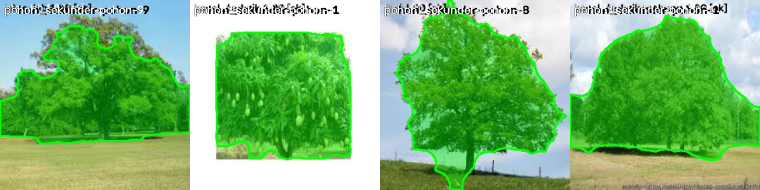

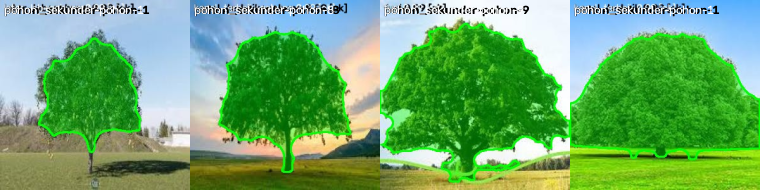


== lubang: 8 skor tertinggi ==


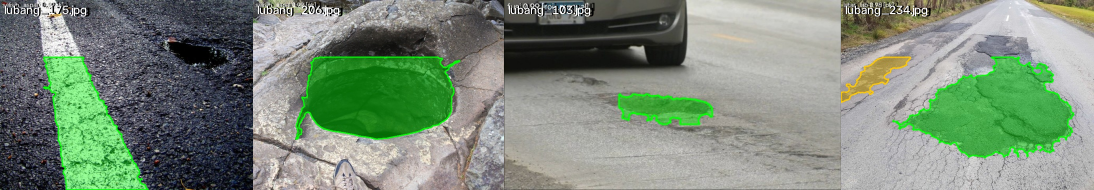

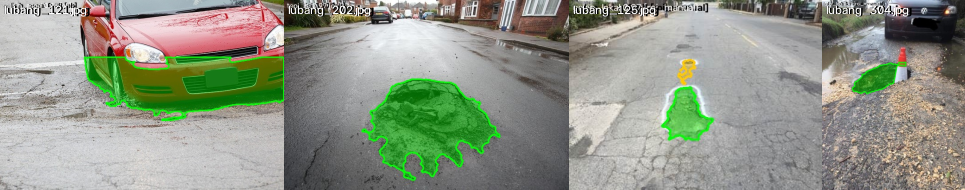


== orang: 8 skor tertinggi ==


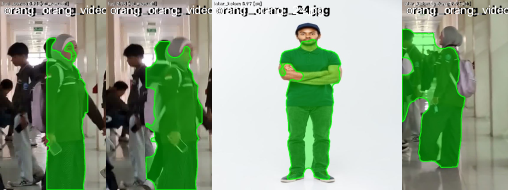

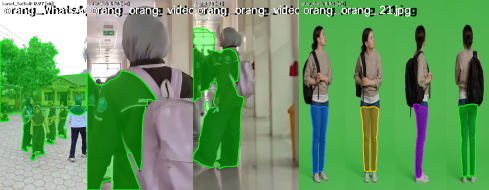


== motor: 8 skor tertinggi ==


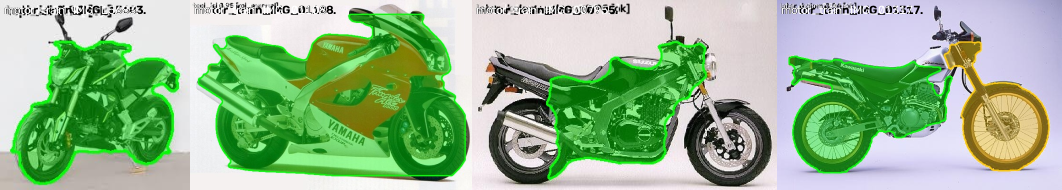

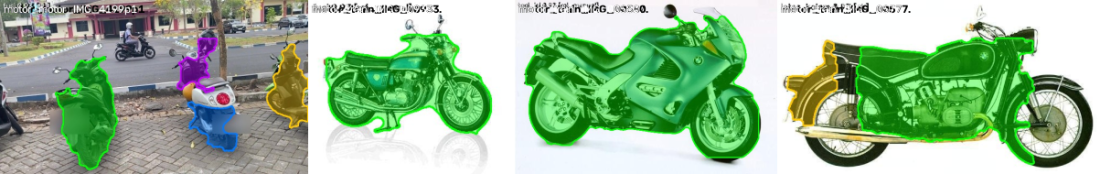


== mobil: 8 skor tertinggi ==


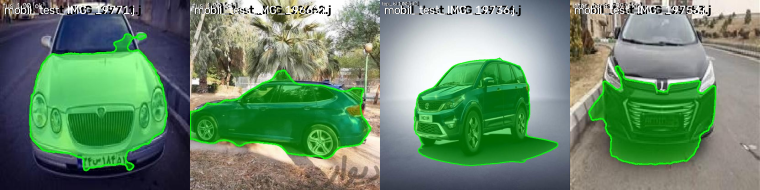

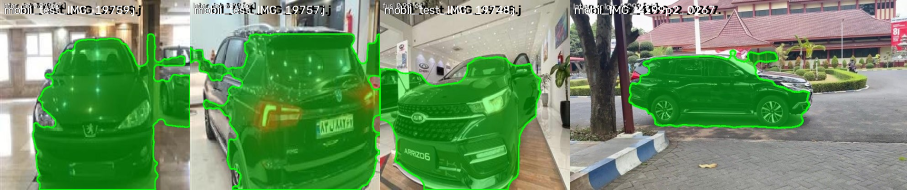

In [24]:
MAKS_GALERI = 8

for k in kelas_list:
    rr = sorted([x for x in laporan if x["kelas"] == k], key=lambda x: -float(x["skor"]))[:MAKS_GALERI]
    if not rr:
        continue
    print(f"\n== {k}: {len(rr)} skor tertinggi ==")
    tampil_baris([(baca_gambar(D_SEG / "overlay" / k / (x["file"].rsplit(".", 1)[0] + ".jpg")), x["file"][:22]) for x in rr])

## 11. Galeri yang perlu dicek (skor terendah)

Gambar berstatus `perlu_cek` / `cadangan_roi`. Bila mask salah, beri ROI manual lewat notebook **02b_koreksi_roi** lalu jalankan ulang notebook ini.

In [25]:
ADA = False
for k in kelas_list:
    rr = sorted([x for x in laporan if x["kelas"] == k and x["status"] in ("perlu_cek", "cadangan_roi")],
                key=lambda x: float(x["skor"]))
    if not rr:
        continue
    ADA = True
    print(f"\n== {k}: {len(rr)} perlu cek, tampil {min(len(rr), MAKS_GALERI)} skor terendah ==")
    tampil_baris([(baca_gambar(D_SEG / "overlay" / k / (x["file"].rsplit(".", 1)[0] + ".jpg")), x["file"][:22]) for x in rr[:MAKS_GALERI]])
if not ADA:
    print("Tidak ada gambar berstatus perlu_cek / cadangan_roi.")

Tidak ada gambar berstatus perlu_cek / cadangan_roi.


## 12. Visualisasi proses satu gambar dari berkas

Membaca kembali `visualisasi_proses/` yang tersimpan: **asli | kontras | tepi Canny | kandidat terbaik | hasil | overlay**.

pohon: pohon_primer-pohon-1.jpg


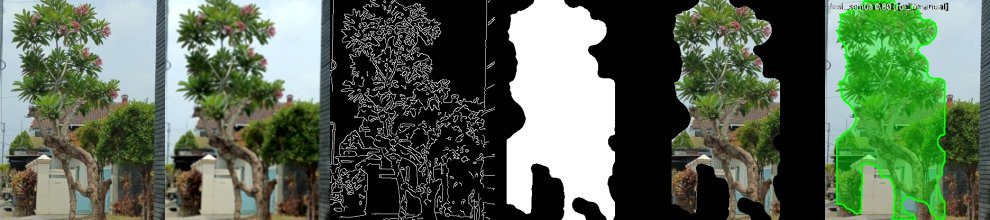

lubang: lubang_1.jpg


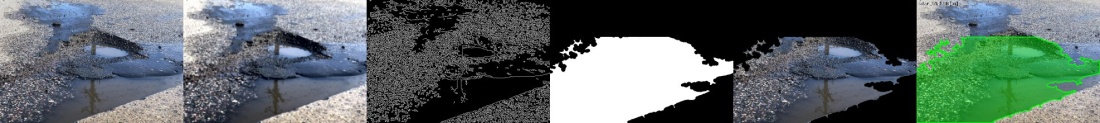

orang: orang_orang_1.jpg


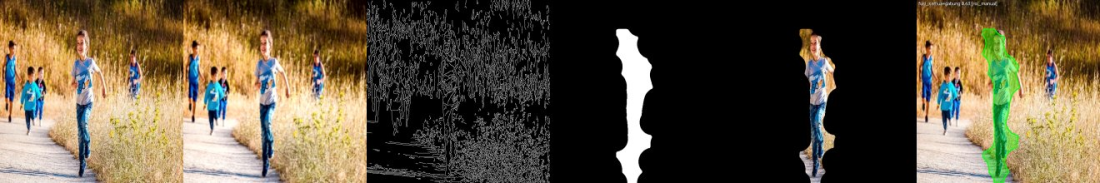

motor: motor_motor_IMG_00556.jpg


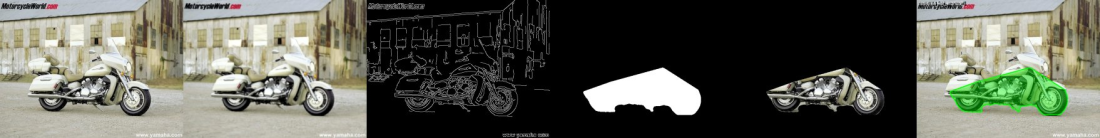

mobil: mobil_IMG_4167.jpg


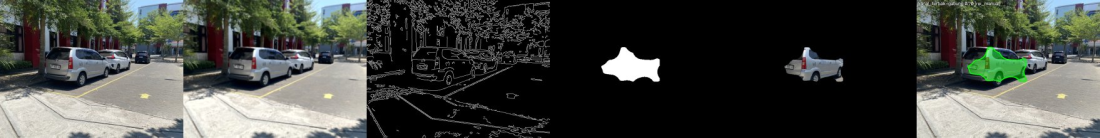

In [26]:
for k in kelas_list:
    fs = daftar_gambar(D_SEG / "visualisasi_proses" / k)
    if fs:
        print(f"{k}: {fs[0].name}")
        tampil(baca_gambar(fs[0]))

## 13. Pemeriksaan akhir

In [27]:
for k in kelas_list:
    n_bersih = len(daftar_gambar(D_CLEAN / "bersih" / k))
    n_mask = len(list((D_SEG / "mask" / k).glob("*.png"))) if (D_SEG / "mask" / k).is_dir() else 0
    print(f"{k:7s} bersih={n_bersih:4d} mask={n_mask:4d}" + ("  (sebagian, karena MAKS)" if MAKS else ""))
log(TAHAP, f"selesai -> {D_SEG}")
if cek:
    log(TAHAP, f"{len(cek)} gambar perlu dicek: lihat perlu_cek.txt (opsional: notebook 02b_koreksi_roi)")
print("\nLanjut ke notebook 02b_koreksi_roi.ipynb (opsional) atau 03_labelling.ipynb")

pohon   bersih= 187 mask= 187
lubang  bersih= 317 mask= 317
orang   bersih= 123 mask= 123
motor   bersih= 220 mask= 220
mobil   bersih= 200 mask= 200
[02_segmentasi] selesai -> C:\Projek\vestcare-dataset\hasil\02_segmentasi

Lanjut ke notebook 02b_koreksi_roi.ipynb (opsional) atau 03_labelling.ipynb
